# Direct Preference Optimization (DPO) con LoRA sobre un modelo pequeño Qwen

[DPO](https://medium.com/the-synaptic-stack/direct-preference-optimization-dpo-an-in-depth-analysis-62a3d1f343a4)

Instalemos las librerías necesarias a usar e instanciemos los datos desde Google Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
!pip install -q trl
!pip install -q -U torchao

Importemos las librerías a usar

In [ ]:
import torch

if torch.cuda.is_available():
    VRAM_GB = round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1)
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", VRAM_GB)
    print("Soporta BF16:", torch.cuda.is_bf16_supported())
else:
    VRAM_GB = 0
    print("Running on CPU")
    print("VRAM (GB):", VRAM_GB)
    print("Soporta BF16: False")


GPU: NVIDIA A100-SXM4-80GB
VRAM (GB): 85.1
Soporta BF16: True


In [ ]:
import json, random
from collections import Counter, defaultdict
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import Dataset, load_dataset
from peft import LoraConfig
from safetensors.torch import load_file
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
)
from trl import DPOConfig, DPOTrainer

W1124 01:13:23.405000 454 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 01:13:23.456000 454 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Definamos los parámetros del modelo

In [ ]:
MODEL_ID = "Qwen/Qwen2.5-Coder-1.5B-Instruct"
DPO_PATH = "/content/drive/MyDrive/GenAI/dpo.jsonl"
MAX_PROMPT_LEN = 2600
MAX_LEN = 3200
OUT_DIR = "/content/drive/MyDrive/GenAI/e2/checkpoints/dpo_lora"
USE_BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
SEED = 42


Importamos el tokenizer de Qwen

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"
tokenizer

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Qwen2Tokenizer(name_or_path='Qwen/Qwen2.5-Coder-1.5B-Instruct', vocab_size=151643, model_max_length=32768, padding_side='left', truncation_side='right', special_tokens={'eos_token': '<|im_end|>', 'pad_token': '<|endoftext|>'}, added_tokens_decoder={
	151643: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151644: AddedToken("<|im_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151645: AddedToken("<|im_end|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151646: AddedToken("<|object_ref_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151647: AddedToken("<|object_ref_end|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151648: AddedToken("<|box_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151649: AddedToken("<|box_end|>", rstri

Carguemos los datos

In [ ]:
rows = [json.loads(line) for line in open(DPO_PATH, encoding='utf-8') if line.strip()]
rows[0], "#################################### uwu ##############################", rows[1:3]

({'task_id': 'hosp_0002',
  'difficulty': 'easy',
  'turn': 'sql',
  'failure_category': 'wrong_answer',
  'prompt': [{'role': 'system',
    'content': "Eres un agente experto en bases de datos SQLite para un entorno hospitalario.\nTu objetivo es responder con exactitud a la pregunta del usuario consultando la base de datos.\n\n### PROTOCOLO DE INTERACCIÓN POR TURNO:\n- Si necesitas consultar la base de datos (o corregir una consulta anterior): emite un bloque <sql>SELECT ...</sql> y detén tu respuesta inmediatamente para esperar el bloque <result>...</result> del sistema.\n- Si ya recibiste un <result>...</result> válido con los datos que responden la pregunta: emite un único bloque <answer>...</answer> con el dato final y termina.\n- Opcionalmente puedes razonar brevemente antes dentro de <think>...</think>.\n- PROHIBIDO incluir <sql> y <answer> en el mismo turno.\n- PROHIBIDO inventar bloques <result>...</result>.\n\n### REGLAS DE SQLITE Y CORRECCIÓN DE ERRORES:\n1. <sql>...</sql>:\

In [ ]:
by_diff = defaultdict(list)
for tid, diff in sorted({(r["task_id"], r["difficulty"]) for r in rows}):
    by_diff[diff].append(tid)
{k: len(v) for k, v in by_diff.items()}

{'easy': 209, 'hard': 273, 'medium': 340, 'expert': 117}

In [ ]:
rng = random.Random(SEED)
for tids in by_diff.values():
    rng.shuffle(tids)
{k: v[:2] for k, v in by_diff.items()}

{'easy': ['hosp_0441', 'hosp_2448'],
 'hard': ['hosp_1155', 'hosp_0224'],
 'medium': ['hosp_0671', 'hosp_1942'],
 'expert': ['hosp_2030', 'hosp_1213']}

Usemos el 10% del dataset para validation (estratificado por dificultad y agrupado por task_id). Por tanto, usaremos un 90% para train split

In [ ]:
VAL_SPLIT_PCT = 0.10
TRAIN_SPLIT_PCT = 1 - VAL_SPLIT_PCT

val_ids = set()
for diff, tids in sorted(by_diff.items()):
    n_val = max(1, int(round(len(tids) * VAL_SPLIT_PCT)))
    val_ids.update(tids[:n_val])
len(val_ids)

94

Obtenemos los datos crudos

In [ ]:
train_raw = [r for r in rows if r["task_id"] not in val_ids]
train_raw[0]

{'task_id': 'hosp_0002',
 'difficulty': 'easy',
 'turn': 'sql',
 'failure_category': 'wrong_answer',
 'prompt': [{'role': 'system',
   'content': "Eres un agente experto en bases de datos SQLite para un entorno hospitalario.\nTu objetivo es responder con exactitud a la pregunta del usuario consultando la base de datos.\n\n### PROTOCOLO DE INTERACCIÓN POR TURNO:\n- Si necesitas consultar la base de datos (o corregir una consulta anterior): emite un bloque <sql>SELECT ...</sql> y detén tu respuesta inmediatamente para esperar el bloque <result>...</result> del sistema.\n- Si ya recibiste un <result>...</result> válido con los datos que responden la pregunta: emite un único bloque <answer>...</answer> con el dato final y termina.\n- Opcionalmente puedes razonar brevemente antes dentro de <think>...</think>.\n- PROHIBIDO incluir <sql> y <answer> en el mismo turno.\n- PROHIBIDO inventar bloques <result>...</result>.\n\n### REGLAS DE SQLITE Y CORRECCIÓN DE ERRORES:\n1. <sql>...</sql>:\n   - 

In [ ]:
val_raw = [r for r in rows if r["task_id"] in val_ids]
val_raw[0]

{'task_id': 'hosp_0047',
 'difficulty': 'hard',
 'turn': 'sql',
 'failure_category': 'wrong_answer',
 'prompt': [{'role': 'system',
   'content': "Eres un agente experto en bases de datos SQLite para un entorno hospitalario.\nTu objetivo es responder con exactitud a la pregunta del usuario consultando la base de datos.\n\n### PROTOCOLO DE INTERACCIÓN POR TURNO:\n- Si necesitas consultar la base de datos (o corregir una consulta anterior): emite un bloque <sql>SELECT ...</sql> y detén tu respuesta inmediatamente para esperar el bloque <result>...</result> del sistema.\n- Si ya recibiste un <result>...</result> válido con los datos que responden la pregunta: emite un único bloque <answer>...</answer> con el dato final y termina.\n- Opcionalmente puedes razonar brevemente antes dentro de <think>...</think>.\n- PROHIBIDO incluir <sql> y <answer> en el mismo turno.\n- PROHIBIDO inventar bloques <result>...</result>.\n\n### REGLAS DE SQLITE Y CORRECCIÓN DE ERRORES:\n1. <sql>...</sql>:\n   - 

In [ ]:
print(f"Train: {len(train_raw)} trazas | Val: {len(val_raw)} trazas")

Train: 1668 trazas | Val: 186 trazas


## Proporciones del dataset

,Dificultad,Train,Train (%),Val,Val (%)
0,easy,355,21.3,40,21.5
1,medium,612,36.7,68,36.6
2,hard,491,29.4,54,29.0
3,expert,210,12.6,24,12.9


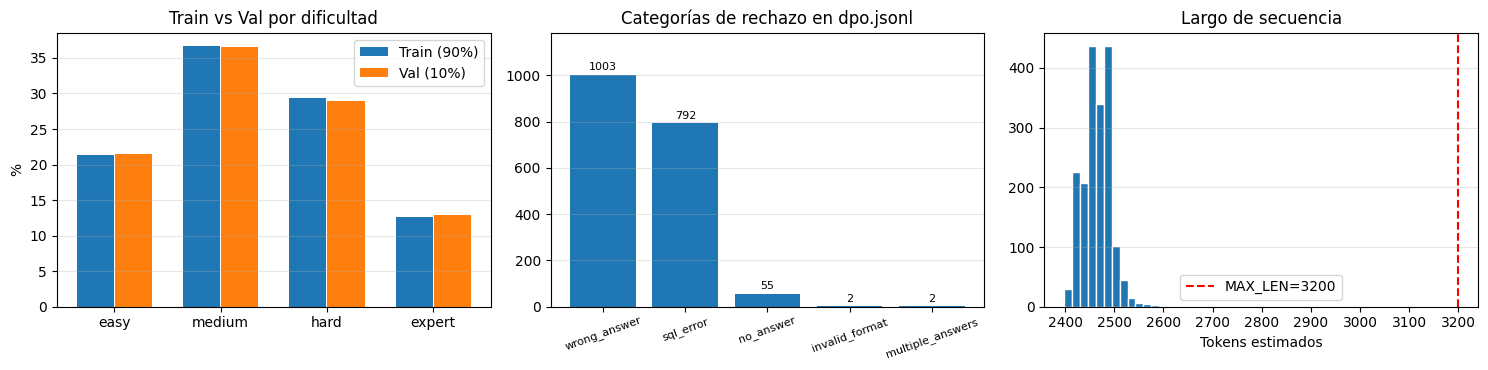

In [ ]:
DIFFS = ["easy", "medium", "hard", "expert"]
tr_diff = Counter(r["difficulty"] for r in train_raw)
va_diff = Counter(r["difficulty"] for r in val_raw)

prop_df = pd.DataFrame([
    {
        "Dificultad": d,
        "Train": tr_diff[d],
        "Train (%)": round(100 * tr_diff[d] / len(train_raw), 1),
        "Val": va_diff[d],
        "Val (%)": round(100 * va_diff[d] / len(val_raw), 1),
    }
    for d in DIFFS
])
display(prop_df)

fail_counts = Counter(r["failure_category"] for r in rows)
fail_keys = [k for k, _ in fail_counts.most_common()]
est_toks = [
    (sum(len(m["content"]) + 20 for m in r["prompt"]) + max(len(r["chosen"]), len(r["rejected"])) + 20) / 3.47
    for r in rows
]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

x = np.arange(len(DIFFS))
axes[0].bar(x - 0.18, prop_df["Train (%)"], width=0.35, label="Train (90%)")
axes[0].bar(x + 0.18, prop_df["Val (%)"], width=0.35, label="Val (10%)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(DIFFS)
axes[0].set_ylabel("%")
axes[0].set_title("Train vs Val por dificultad")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(fail_keys, [fail_counts[k] for k in fail_keys])
for i, k in enumerate(fail_keys):
    axes[1].text(i, fail_counts[k] + 20, f"{fail_counts[k]}", ha="center", fontsize=8)
axes[1].set_ylim(0, max(fail_counts.values()) * 1.18)
axes[1].set_title("Categorías de rechazo en dpo.jsonl")
axes[1].tick_params(axis="x", rotation=20, labelsize=8)
axes[1].grid(axis="y", alpha=0.3)

axes[2].hist(est_toks, bins=35, edgecolor="white")
axes[2].axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN={MAX_LEN}")
axes[2].set_xlabel("Tokens estimados")
axes[2].set_title("Largo de secuencia")
axes[2].legend()
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Tokenización

Podriamos usa `apply_chat_template` de HuggingFace, que viene ya con el tokenizer. Pero no quize usarlo por ahora, aunque podría ser recomendable solo por mantener la consistencia. Pero habría que verificar que realmente es correcto el método. Además, igualmente habría que enmascarar con -100 las partes que no queremos que aprenda el modelo.

In [ ]:
def format_dpo(row):
    return {
        "prompt": row["prompt"],
        "chosen": [{"role": "assistant", "content": row["chosen"]}],
        "rejected": [{"role": "assistant", "content": row["rejected"]}],
    }

In [ ]:
train_ds = Dataset.from_list([format_dpo(r) for r in train_raw])
val_ds   = Dataset.from_list([format_dpo(r) for r in val_raw])

## Verificación de tokenización correcta

In [ ]:
sample = train_ds[0]
print("Prompt turns:", len(sample["prompt"]))
print("CHOSEN:  ", sample["chosen"][0]["content"])
print("REJECTED:", sample["rejected"][0]["content"])

Prompt turns: 2
CHOSEN:   <sql>SELECT SUM(c.cost) FROM appointments c WHERE c.diagnosis = 'Control sano' AND strftime('%Y', c.appointment_date) = '2025'</sql>
REJECTED: <sql>SELECT SUM(c.cost) FROM consults c INNER JOIN patients p ON c.patient_id = p.patient_id WHERE p.city = 'Santiago' AND c.diagnosis = 'Control sano' AND strftime('%Y', c.appointment_date) = '2025'</sql>


## Instanciar el modelo LoRa

In [ ]:
# Cargamos modelo base en BF16 (L4/A100/G4) o FP16 (T4)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.bfloat16 if USE_BF16 else torch.float16,
    device_map="auto",
)
model.config.use_cache = False

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## Inyectar adaptadores LoRA

In [ ]:
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)

Se identifican trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820

## Entrenar y guardar adaptador LoRA

Definimos aqui en la misma celda los hiperparámetros

In [ ]:
batch_size = 2 if VRAM_GB >= 40 else 1
grad_accum = 8 if VRAM_GB >= 40 else 16
use_ckpt = False

training_args = DPOConfig(
    output_dir=OUT_DIR,
    beta=0.1,
    num_train_epochs=2,
    per_device_train_batch_size=batch_size,
    gradient_accumulation_steps=grad_accum,
    per_device_eval_batch_size=1,
    learning_rate=5e-6,
    lr_scheduler_type="cosine",
    warmup_steps=15,
    weight_decay=0.01,
    max_grad_norm=1.0,
    max_length=MAX_LEN,
    gradient_checkpointing=use_ckpt,
    gradient_checkpointing_kwargs={"use_reentrant": False} if use_ckpt else None,
    bf16=USE_BF16,
    fp16=not USE_BF16,
    logging_steps=5,
    eval_strategy="steps",
    eval_steps=25,
    save_strategy="epoch",
    save_total_limit=3,
    report_to="none",
    seed=SEED,
)

trainer = DPOTrainer(
    model=model,
    ref_model=None,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    peft_config=lora_config,
)
trainer.model.print_trainable_parameters()
train_result = trainer.train()

/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:148: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


Tokenizing train dataset:   0%|          | 0/1668 [00:00<?, ? examples/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/1668 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/186 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset:   0%|          | 0/186 [00:00<?, ? examples/s]

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
25,0.690312,0.691463,0.232405,1932643.000000,-3.300801,-3.294361,0.971093,0.000583,-0.002861,0.607527,0.003444,-6.774584,-9.721346
50,0.669577,0.675066,0.226800,3866848.000000,-3.314713,-3.307240,0.971004,0.007358,-0.029970,0.758065,0.037328,-6.706832,-9.992436
75,0.642685,0.644603,0.217344,5801365.000000,-3.344040,-3.335230,0.969789,0.003428,-0.101507,0.817204,0.104935,-6.746127,-10.707800
100,0.610563,0.608605,0.205799,7734830.000000,-3.377490,-3.366978,0.967957,-0.011792,-0.205521,0.838710,0.193729,-6.898329,-11.747943
125,0.528022,0.574239,0.196830,9610183.000000,-3.414492,-3.402692,0.966357,-0.044414,-0.335297,0.817204,0.290883,-7.224552,-13.045703
150,0.520852,0.553434,0.189575,11544359.000000,-3.440361,-3.427510,0.965683,-0.068749,-0.425239,0.844086,0.356491,-7.467897,-13.945128


Run simple para ver si funciona el script

In [ ]:
# import gc, torch
# gc.collect()
# torch.cuda.empty_cache()

# smoke_args = DPOConfig(
#     output_dir=OUT_DIR,
#     beta=0.1,
#     max_steps=5,
#     per_device_train_batch_size=1,
#     gradient_accumulation_steps=4,
#     per_device_eval_batch_size=1,
#     learning_rate=5e-6,
#     max_length=MAX_LEN,
#     max_prompt_length=MAX_PROMPT_LEN,
#     gradient_checkpointing=True,
#     gradient_checkpointing_kwargs={"use_reentrant": False},
#     bf16=USE_BF16,
#     fp16=not USE_BF16,
#     logging_steps=1,
#     eval_strategy="steps",
#     eval_steps=5,
#     save_strategy="no",
#     report_to="none",
#     seed=SEED,
# )
# trainer = DPOTrainer(
#     model=model,
#     ref_model=None,
#     args=smoke_args,
#     train_dataset=train_ds,
#     eval_dataset=val_ds.select(range(10)),
#     processing_class=tokenizer,
#     peft_config=lora_config,
# )
# train_result = trainer.train()

Guardamos el modelo en Google Drive, muy importante ! ! !

In [ ]:
## Guardar adaptador final
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
final_name = f"final_{timestamp}"
final_dir = Path(OUT_DIR) / final_name
final_dir.mkdir(parents=True, exist_ok=True)

trainer.save_model(str(final_dir))
tokenizer.save_pretrained(str(final_dir))

logs = trainer.state.log_history
with open(final_dir / "log_history.json", "w", encoding="utf-8") as f:
    json.dump(logs, f, indent=2, ensure_ascii=False)

run_meta = {
    "model_id": MODEL_ID,
    "gpu": torch.cuda.get_device_name(0),
    "vram_gb": VRAM_GB,
    "vram_peak_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2),
    "max_len": MAX_LEN,
    "seed": SEED,
    "val_split_pct": VAL_SPLIT_PCT,
    "n_train": len(train_raw),
    "n_val": len(val_raw),
    "train_loss": float(train_result.training_loss),
    "global_step": trainer.state.global_step,
    "val_ids": sorted(val_ids),
    "beta": 0.1
}
with open(final_dir / "run_metadata.json", "w", encoding="utf-8") as f:
    json.dump(run_meta, f, indent=2, ensure_ascii=False)

adapter_path = final_dir / "adapter_model.safetensors"
assert adapter_path.exists()
tensors = load_file(str(adapter_path))
lora_b_norms = [float(v.float().norm().item()) for k, v in tensors.items() if "lora_B" in k]
assert max(lora_b_norms) > 0
print(f"Guardado OK en {final_dir} | {adapter_path.stat().st_size / (1024**2):.2f} MB | lora_B norm mean={np.mean(lora_b_norms):.4f}")

## Evaluación

Graficamos la pérdida obtenida

In [ ]:
train_steps = [x["step"] for x in logs if "loss" in x]
train_loss  = [x["loss"] for x in logs if "loss" in x]
eval_steps  = [x["step"] for x in logs if "eval_loss" in x]
eval_loss   = [x["eval_loss"] for x in logs if "eval_loss" in x]
lr_steps    = [x["step"] for x in logs if "learning_rate" in x]
lrs         = [x["learning_rate"] for x in logs if "learning_rate" in x]
gn_steps    = [x["step"] for x in logs if "grad_norm" in x]
grad_norms  = [x["grad_norm"] for x in logs if "grad_norm" in x]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(train_steps, train_loss, label="Train Loss (DPO)")
axes[0].plot(eval_steps, eval_loss, marker="o", label=f"Val Loss ({int(VAL_SPLIT_PCT*100)}% tareas)")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("DPO Loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(lr_steps, lrs, color="tab:green")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("LR")
axes[1].set_title("Learning Rate")
axes[1].grid(True, alpha=0.3)

axes[2].plot(gn_steps, grad_norms, color="tab:orange")
axes[2].set_xlabel("Step")
axes[2].set_ylabel("Grad Norm")
axes[2].set_title("Gradient Norm")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/{final_name}/dpo_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
margin_steps = [x["step"] for x in logs if "rewards/margins" in x]
margins      = [x["rewards/margins"] for x in logs if "rewards/margins" in x]
eval_m_steps = [x["step"] for x in logs if "eval_rewards/margins" in x]
eval_margins = [x["eval_rewards/margins"] for x in logs if "eval_rewards/margins" in x]

acc_steps    = [x["step"] for x in logs if "rewards/accuracies" in x]
accs         = [x["rewards/accuracies"] for x in logs if "rewards/accuracies" in x]
eval_a_steps = [x["step"] for x in logs if "eval_rewards/accuracies" in x]
eval_accs    = [x["eval_rewards/accuracies"] for x in logs if "eval_rewards/accuracies" in x]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(margin_steps, margins, label="Train Margin")
axes[0].plot(eval_m_steps, eval_margins, marker="o", label="Val Margin")
axes[0].axhline(0, color="gray", linestyle="--", alpha=0.6)
axes[0].set_xlabel("Step")
axes[0].set_ylabel("r_chosen - r_rejected")
axes[0].set_title("Reward Margin")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(acc_steps, accs, label="Train Accuracy")
axes[1].plot(eval_a_steps, eval_accs, marker="o", label="Val Accuracy")
axes[1].axhline(0.5, color="gray", linestyle="--", alpha=0.6)
axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Accuracy (chosen > rejected)")
axes[1].set_title("Preference Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/{final_name}/dpo_rewards_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
datetime.now()

datetime.datetime(2026, 11, 24, 2, 16, 44, 229363)